In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [51]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    cutDataframe = dataframe.query(cut)
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [31]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [4]:
df_allreco = applyCut(pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc.csv', low_memory=False),\
                      'pts>15 and bs!=-9 and w<1')

In [33]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

# Process PYTHIA6+GEANT

In [5]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [5]:
print(df_match.shape[0], df_allfake.shape[0])

2623349 1471810


In [52]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]]

In [53]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [8]:
plt.rcParams['font.size'] = 12

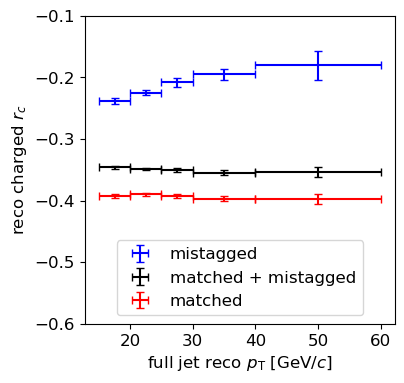

In [9]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [9]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [54]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [55]:
b_fake_array

[array([0.61905176, 0.38094824]),
 array([0.61242198, 0.38757802]),
 array([0.60408262, 0.39591738]),
 array([0.5976935, 0.4023065]),
 array([0.59006909, 0.40993091])]

In [56]:
b_match_array = []
b_match_err_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    p = y_reco[0]/sum(y_reco)
    q = y_reco[1]/sum(y_reco)
    print(np.array([p,q]))
    eff_count,eff_count_err,x = calc_hist(df_match_pts[ob+'s'], bins=[range_low, range_high], weights=df_match_pts['ws'], density=True)
    #print("count, err", eff_count,eff_count_err)
    sqrt_n_over_n = eff_count_err[0]/eff_count[0]
    #print((1/sqrt_n_over_n)**2)
    b_match_err_array.append(np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))
    print(np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))

[0.69613888 0.30386112]
[0.0014672 0.0014672]
[0.69480417 0.30519583]
[0.00127937 0.00127937]
[0.69601126 0.30398874]
[0.00168057 0.00168057]
[0.69844548 0.30155452]
[0.00208956 0.00208956]
[0.69854114 0.30145886]
[0.00425396 0.00425396]


In [21]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_1059341/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [22]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29936704, 0.24871283, 0.22295968, 0.20754411, 0.19886014])

# Process data

In [13]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [14]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [15]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [16]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [17]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

In [18]:
print(b_data_array)

[array([337314., 178144.]), array([72379., 38554.]), array([16450.,  8688.]), array([4758., 2573.]), array([334., 153.])]


# 1. Mistagged subtraction

In [19]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [16]:
#fake_rate_array = np.array([0.29936704, 0.24871283, 0.22295968, 0.20754411, 0.19886014])
#b_fake_array = np.array([[0.61905176, 0.38094824],[0.61242198, 0.38757802],[0.60408262, 0.39591738],[0.5976935, 0.4023065],[0.59006909, 0.40993091]])

In [26]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print("pT bin", i)
    print("b_array raw data", b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, _ = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    print("b_array fake subtracted", b_fakesubtracted)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )
    b_fakesubtractederr = np.array([np.sqrt(p*(1-p)/n), np.sqrt(p*(1-p)/n)])*sum(b_fakesubtracted) # first find sigma(p), then scale up
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print("b_array unc.", b_fakesubtractederr)
    print("b_array frac. unc.", b_fakesubtractederr/b_fakesubtracted)

pT bin 0
b_array raw data [337314. 178144.]
b_array fake subtracted [241787.4194556  119359.44336324]
b_array unc. [282.68536116 282.68536116]
b_array frac. unc. [0.00116915 0.00236835]
pT bin 1
b_array raw data [72379. 38554.]
b_array fake subtracted [55481.99560278 27860.54405046]
b_array unc. [136.18756914 136.18756914]
b_array frac. unc. [0.00245463 0.00488819]
pT bin 2
b_array raw data [16450.  8688.]
b_array fake subtracted [13064.26158427  6468.97787029]
b_array unc. [65.77685877 65.77685877]
b_array frac. unc. [0.00503487 0.01016805]
pT bin 3
b_array raw data [4758. 2573.]
b_array fake subtracted [3848.60584569 1960.88829996]
b_array unc. [36.0420086 36.0420086]
b_array frac. unc. [0.00936495 0.01838045]
pT bin 4
b_array raw data [334. 153.]
b_array fake subtracted [276.85482568 113.30028798]
b_array unc. [8.96649899 8.96649899]
b_array frac. unc. [0.03238701 0.07913924]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

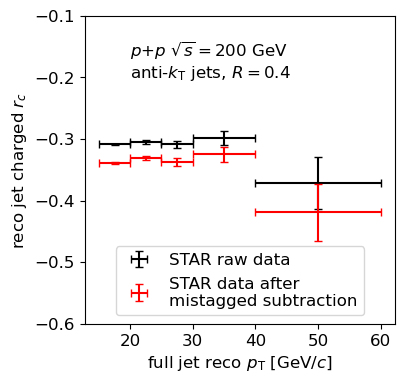

In [24]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [57]:
reweight_array = []
reweight_err_array = []
for i in range(0,5):
    numerator = b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i])
    denominator = b_match_array[i]/sum(b_match_array[i])
    numerator_err = b_fakesubtractederr_array[i]/sum(b_fakesubtracted_array[i])
    print(numerator_err/numerator)
    denominator_err = b_match_err_array[i]/sum(b_match_array[i])
    print(denominator_err/denominator)
    reweight = numerator/denominator
    reweight_err = reweight*np.sqrt((numerator_err/numerator)**2+(denominator_err/denominator)**2)
    reweight_array.append(reweight)
    reweight_err_array.append(reweight_err)

[0.00116915 0.00236835]
[0.00210763 0.00482853]
[0.00245463 0.00488819]
[0.00184134 0.00419197]
[0.00503487 0.01016805]
[0.00241458 0.0055284 ]
[0.00936495 0.01838045]
[0.00299172 0.00692928]
[0.03238701 0.07913924]
[0.00608977 0.01411123]


In [58]:
reweight_array

[array([0.96173177, 1.08767165]),
 array([0.95812666, 1.09532821]),
 array([0.9609357 , 1.08944143]),
 array([0.94848967, 1.11930564]),
 array([1.01583414, 0.96330909])]

In [59]:
reweight_err_array

[array([0.00231795, 0.00584959]),
 array([0.00294002, 0.00705335]),
 array([0.00536578, 0.01260895]),
 array([0.0093248 , 0.02198676]),
 array([0.03347637, 0.07743799])]

([], [])

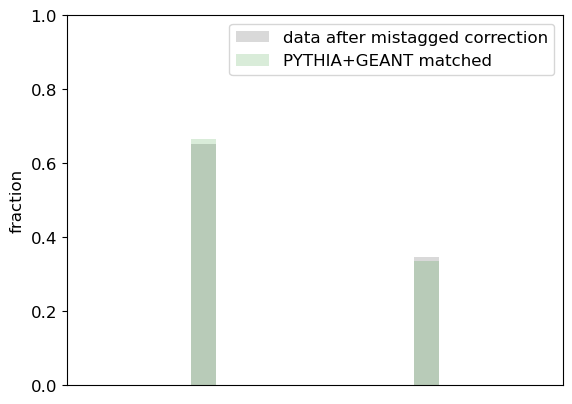

In [63]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [63]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

KeyboardInterrupt: 

In [64]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    print(p)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [116]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]

In [117]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])

0.33188714307254435
0.33188714307254435
0.34090585939830115
0.34090585939830115
0.340880346110499
0.340880346110499
0.34321486736185264
0.34321486736185264
0.3329338876846474
0.3329338876846474


In [118]:
rc_match_bs_vs_pt_array

[-0.33622571385491123,
 -0.3181882812033978,
 -0.31823930777900206,
 -0.31357026527629467,
 -0.3341322246307052]

In [119]:
rc_err_match_bs_vs_pt_array

[0.0029097490942195815,
 0.002264048030301498,
 0.0028234793221461737,
 0.00351043200986792,
 0.005306904669499476]

# Check thesis formula

In [87]:
binedges = np.array([15, 20, 25, 30, 40, 60])

In [33]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p_final = nss/(nss+nos)
    print(p_final)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err, p_final

## Truth $p_T\in$ (15, 20) GeV

In [137]:
df_match_cut = applyCut(df_match, '15<pt<20')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [138]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.3062855273753735
0.29145912186424
0.2548663415639463
0.4028557241691663
0.2867706788974019


In [139]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '15<pt<20 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>15) & (df_match_cut.pt<20)]['w'])/sum(df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)]['w']))
prob_array

[0.9207047759814123,
 0.07799696183274929,
 0.0012430239411480508,
 5.3444209575527985e-05,
 1.7921020340868551e-06]

In [140]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3319915741457225

In [141]:
rc_rwerr_match_bs_vs_pt_array = []

In [142]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0016573542403515704


In [127]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '15<pt<20 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>15) & (df_match_cut.pt<20)]['w'])/sum(df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)]['w']))
prob_array

[0.9151564796850777,
 0.08321193656851017,
 0.0015948574585246446,
 3.476570790519904e-05,
 1.9560405832772186e-06]

In [128]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6682157410978843

In [115]:
0.3319915741457225/(0.3319915741457225+0.6682157410978843)

0.331922761497564

## Truth $p_T\in$ (20,25) GeV

In [143]:
df_match_cut = applyCut(df_match, '20<pt<25')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [144]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.3207653038345011
0.3089501344205579
0.2916239545871971
0.2569386117394937
0.11103411595080429


In [145]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '20<pt<25 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>20) & (df_match_cut.pt<25)]['w'])/sum(df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)]['w']))
prob_array

[0.4098862577769719,
 0.5330160876097,
 0.05542800816895412,
 0.0016631014354267387,
 6.5183035392636705e-06]

In [146]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.34146659350156494

In [147]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0014079195086317176


In [134]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '20<pt<25 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>20) & (df_match_cut.pt<25)]['w'])/sum(df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)]['w']))
prob_array

[0.3945800048835653,
 0.5420015832281795,
 0.06120814017590142,
 0.0021865192207058855,
 2.372479537496792e-05]

In [135]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6598495934660082

In [136]:
0.34146659350156494/(0.34146659350156494+0.6598495934660082)

0.3410177503828

## Truth $p_T\in$ (25, 30) GeV

In [148]:
df_match_cut = applyCut(df_match, '25<pt<30')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [149]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.30371844717252744
0.3236422272607208
0.30816585892711973
0.287519140404702
0.1719999210478101


In [150]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '25<pt<30 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>25) & (df_match_cut.pt<30)]['w'])/sum(df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)]['w']))
prob_array

[0.11155869730421943,
 0.39056867938889145,
 0.438181322992927,
 0.05953759222673492,
 0.00015352693146433786]

In [151]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3416033551169046

In [152]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0019684414541198346


In [141]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '25<pt<30 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>25) & (df_match_cut.pt<30)]['w'])/sum(df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)]['w']))
prob_array

[0.11604107237568952,
 0.3703422819561627,
 0.4463401045541351,
 0.06694101430437228,
 0.0003353368506935604]

In [142]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6599506071523044

In [143]:
0.3416033551169046/(0.3416033551169046+0.6599506071523044)

0.34107334001548745

## Truth $p_T\in$ (30, 40) GeV

In [153]:
df_match_cut = applyCut(df_match, '30<pt<40')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [154]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.28316726939208137
0.312804485069363
0.32267979995173374
0.3078177404943276
0.29013209461534556


In [155]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '30<pt<40 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>30) & (df_match_cut.pt<40)]['w'])/sum(df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)]['w']))
prob_array

[0.04195230335095665,
 0.12298897141520168,
 0.3290355577524411,
 0.4891550158086249,
 0.016865371637292074]

In [156]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.34397750459553056

In [157]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0036019505128177536


In [148]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '30<pt<40 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>30) & (df_match_cut.pt<40)]['w'])/sum(df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)]['w']))
prob_array

[0.04809251530119332,
 0.12235463384086036,
 0.3127605653780106,
 0.49810423793932773,
 0.018686354806695987]

In [149]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6577736278276134

In [150]:
0.34397750459553056/(0.34397750459553056+0.6577736278276134)

0.34337620738544167

## Truth $p_T\in$ (40, 60) GeV

In [31]:
df_match_cut = applyCut(df_match, '40<pt<60')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [34]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.28959706328906154
0.31010755344048496
0.30695872107519157
0.3234305139550745
0.31483922610251336


In [160]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '40<pt<60 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>40) & (df_match_cut.pt<60)]['w'])/sum(df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)]['w']))
prob_array

[0.014622547924954404,
 0.03500030689545648,
 0.07443239316013701,
 0.45618413517063383,
 0.41877634116171464]

In [161]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3335419541815301

In [162]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.010717128373808445


In [35]:
print(reweight_err_array[0][1]*p_match_bs_vs_pt_array[0])
print(reweight_err_array[1][1]*p_match_bs_vs_pt_array[1])
print(reweight_err_array[2][1]*p_match_bs_vs_pt_array[2])
print(reweight_err_array[3][1]*p_match_bs_vs_pt_array[3])
print(reweight_err_array[4][1]*p_match_bs_vs_pt_array[4])

0.0016940229377135254
0.0021872976147541646
0.003870428364057778
0.007111188895462932
0.02438051639269022


In [161]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '40<pt<60 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>40) & (df_match_cut.pt<60)]['w'])/sum(df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)]['w']))
prob_array

[0.016680902164788267,
 0.03620985493298562,
 0.07814964255957876,
 0.4437695312428447,
 0.4238104688952175]

In [162]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6671283343492007

In [163]:
np.sqrt((reweight_err_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0])**2+\
        (reweight_err_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1])**2+\
        (reweight_err_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2])**2+\
        (reweight_err_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3])**2+\
        (reweight_err_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4])**2)

0.018692048828532523

In [157]:
0.3335419541815301/(0.3335419541815301+0.6671283343492007)

0.3333185345907139

# Plot result

In [120]:
rc_rwerr_match_bs_vs_pt_array = np.asarray(rc_rwerr_match_bs_vs_pt_array)
rc_err_match_bs_vs_pt_array = np.asarray(rc_err_match_bs_vs_pt_array)
rc_err_tot = np.sqrt(rc_rwerr_match_bs_vs_pt_array**2+rc_err_match_bs_vs_pt_array**2)
print("central rc values:", rc_match_bs_vs_pt_array)
print("uncertainties from reweighting factors:", rc_rwerr_match_bs_vs_pt_array)
print("uncertainties from PYTHIA jets:", rc_err_match_bs_vs_pt_array)
print("total statistical uncertainties:", rc_err_tot)

central rc values: [-0.33622571385491123, -0.3181882812033978, -0.31823930777900206, -0.31357026527629467, -0.3341322246307052]
uncertainties from reweighting factors: [0.00390657 0.00313129 0.00414961 0.0074104  0.02155607]
uncertainties from PYTHIA jets: [0.00290975 0.00226405 0.00282348 0.00351043 0.0053069 ]
total statistical uncertainties: [0.00487113 0.00386405 0.0050191  0.00819982 0.02219971]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

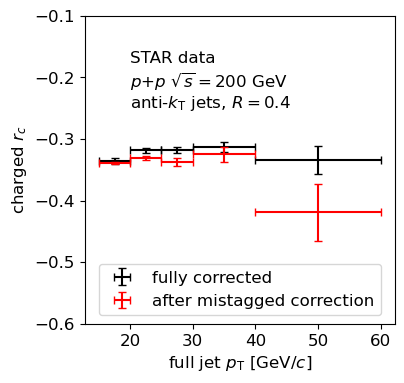

In [121]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_tot, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# Check $r_c$ correction is not needed

Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

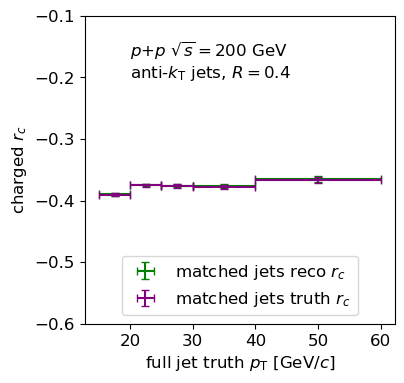

In [29]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='g', ls='none', label='matched jets reco $r_c$')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_b_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_b_vs_pt_array, capsize=3, color='purple', ls='none', label='matched jets truth $r_c$')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# Check statistical uncertainties

In [75]:
y_data, y_data_err,_ = calc_hist(df_data['pts'], bins=np.array([15, 20, 25, 30, 40, 60]), weights=np.ones(df_data.shape[0]))
print(y_data)
print(y_data_err)

[5.15458e+05 1.10933e+05 2.51380e+04 7.33100e+03 4.87000e+02]
[717.95403753 333.06605951 158.54967676  85.62125904  22.06807649]


## How many matched jets (i.e., after mistagged subtraction) in data have truth 40 < $p_T$ < 60 GeV?

In [77]:
prob_array = []
pts_array = np.array([15,20,25,30,40,60]) 
for i in range(0,len(pts_array)-1):
    # for a reco jet of 15-20, what is the prob that it comes from truth 40-60?
    prob_array.append(sum(df_match[(df_match.pt>40) & (df_match.pt<60) & (df_match.pts>pts_array[i]) & (df_match.pts<pts_array[i+1])]['w'])/sum(df_match[(df_match.pts>pts_array[i]) & (df_match.pts<pts_array[i+1])]['w']))
print(prob_array)                

[2.0571997650051865e-05, 0.00020943496238096527, 0.0019921197938721764, 0.03856285907955857, 0.5839997156683072]


In [81]:
njet_40pt60 = 0
err2 = 0
for i in range(0,len(pts_array)-1):
    n = sum(b_fakesubtracted_array[i])*prob_array[i]
    err = sum(b_fakesubtractederr_array[i])*prob_array[i]
    print("N(jets) with truth pT of 40-60 and reco pT of", pts_array[i], "-", pts_array[i+1], ":", n, "+/-", err)
    njet_40pt60 += y_data[i]*prob_array[i]
    err2 += err**2
print("total N(jets) with truth pT of 40-60:", njet_40pt60, ", relative unc.:", np.sqrt(err2)/njet_40pt60)

N(jets) with truth pT of 40-60 and reco pT of 15 - 20 : 7.4295124132327715 +/- 0.01722294231228063
N(jets) with truth pT of 40-60 and reco pT of 20 - 25 : 17.454841657011404 +/- 0.08428939293580652
N(jets) with truth pT of 40-60 and reco pT of 25 - 30 : 38.91255295587341 +/- 0.3879234098808002
N(jets) with truth pT of 40-60 and reco pT of 30 - 40 : 224.0307040623581 +/- 4.099966589997732
N(jets) with truth pT of 40-60 and reco pT of 40 - 60 : 227.85047544404034 +/- 15.933390308180302
total N(jets) with truth pT of 40-60: 651.0273382675763 , relative unc.: 0.02527886719910261
